# Backbone Model - Huấn luyện mô hình sử dụng backbone EfficientNet-B0

---

Mục tiêu là sử dụng mô hình `EfficientNet-B0` để huấn luyện mô hình dự đoán quét mặt gian lận

In [1]:
import os
import sys
import math
import numpy as np
from pathlib import Path

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0' 

import tensorflow as tf
from keras.models import load_model, Sequential
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation, RandomContrast, RandomBrightness
from keras.optimizers import AdamW
from keras.optimizers.schedules import CosineDecay
from keras.losses import BinaryFocalCrossentropy
from keras.callbacks import EarlyStopping
from keras.utils import set_random_seed, image_dataset_from_directory
from sklearn.metrics import classification_report

sys.path.append(os.path.abspath('..'))
from models.BackboneModel import backbone_model
from src.evaluate import MetricsCallback, plot_training_history, evaluate_model, calculate_metrics

I0000 00:00:1791684972.678796  163138 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
IMG_SIZE = 224
EPOCHS = 30
WARMUP_EPOCHS = 5
LR_WARMUP_EPOCHS = 2
BATCH_SIZE = 32
SEED = 42
DATA_DIR = Path('../datasets/LCC_FASD')
OUTPUT_DIR = Path('../outputs/backbone-model')
CACHE_DIR = Path('../cache/backbone-model')

set_random_seed(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chuẩn bị dữ liệu

---

In [3]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(factor=0.015, fill_mode='nearest'),
    RandomZoom(height_factor=(-0.1, 0.0), width_factor=(-0.1, 0.0)),
    RandomTranslation(height_factor=0.1, width_factor=0.1, fill_mode='nearest'),
    RandomContrast(factor=0.2),
    RandomBrightness(factor=0.1)
])

E0000 00:00:1791684975.513398  163138 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
train_dir = DATA_DIR / 'train'
val_dir = DATA_DIR / 'val'
test_dir = DATA_DIR / 'test'

print("Tập Train:")
train_ds_raw = image_dataset_from_directory(
    train_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=True,
    seed=SEED
)

print("\nTập Validation:")
val_ds_raw = image_dataset_from_directory(
    val_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("\nTập Test:")
test_ds_raw = image_dataset_from_directory(
    test_dir, 
    image_size=(IMG_SIZE, IMG_SIZE), 
    batch_size=None, 
    label_mode='binary',
    shuffle=False
)

print("Class:", train_ds_raw.class_names)

Tập Train:
Found 8299 files belonging to 2 classes.

Tập Validation:
Found 2948 files belonging to 2 classes.

Tập Test:
Found 7580 files belonging to 2 classes.
Class: ['real', 'spoof']


In [5]:
AUTOTUNE = tf.data.AUTOTUNE
to_uint8 = lambda x, y: (tf.cast(tf.round(x), tf.uint8), y)
to_float = lambda x, y: (tf.cast(x, tf.float32), y)
augment  = lambda x, y: (data_augmentation(tf.cast(x, tf.float32), training=True), y)

def make_cached(ds, path=None):
    ds = ds.map(to_uint8)
    ds = ds.cache(str(path)) if path else ds.cache()
    for _ in ds:
        pass
    return ds

train_c = make_cached(train_ds_raw)                      
val_c   = make_cached(val_ds_raw)                       
test_c  = make_cached(test_ds_raw, CACHE_DIR / 'test') 

train_ds = (train_c.shuffle(2000, seed=SEED).batch(BATCH_SIZE).map(augment, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE))
val_ds  = val_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)
test_ds = test_c.batch(BATCH_SIZE).map(to_float).prefetch(AUTOTUNE)

W0000 00:00:1791684996.994047  163138 cache_dataset_ops.cc:330] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


## 2. Khởi tạo mô hình

---

Mô hình được xây dựng trong [BackboneModel](../models/BackboneModel.py)

In [6]:
input_shape = (IMG_SIZE, IMG_SIZE, 3)

model = backbone_model(input_shape=input_shape, num_classes=1, freeze_backbone=True)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,410,532 (16.82 MB)

 Trainable params: 360,961 (1.38 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [7]:
labels = ["real", "spoof"]
real_counts = 0
spoof_counts = 0

for label in labels:
    label_dir = os.path.join(train_dir, label)
    count = len(os.listdir(label_dir))
    if label == "real":
        real_counts = count
    else:
        spoof_counts = count
    print(f"Số lượng ảnh {label}: {count}")

total_counts = real_counts + spoof_counts
print(f"Tổng số lượng ảnh: {total_counts}")
class_weights = {0: total_counts / (2 * real_counts), 1: total_counts / (2 * spoof_counts)}
print(f"Class weights: {class_weights}")

Số lượng ảnh real: 1223
Số lượng ảnh spoof: 7076
Tổng số lượng ảnh: 8299
Class weights: {0: 3.392886345053148, 1: 0.5864188807235726}


In [8]:
metrics_callback = MetricsCallback(val_dataset=val_ds, save_dir=OUTPUT_DIR)

callbacks = [
    metrics_callback,

    EarlyStopping(
        monitor='val_acer',
        patience=6,
        mode='min',
        restore_best_weights=True,
        verbose=1
    )
]

steps_per_epoch = math.ceil(len(train_ds_raw) / BATCH_SIZE)

lr_schedule_stage_1 = CosineDecay(
    initial_learning_rate=0.000363,
    decay_steps=EPOCHS * steps_per_epoch
)

lr_schedule_stage_2 = CosineDecay(
    initial_learning_rate=1e-6,
    warmup_target=1e-5,
    warmup_steps=LR_WARMUP_EPOCHS * steps_per_epoch,
    decay_steps=(EPOCHS - WARMUP_EPOCHS - LR_WARMUP_EPOCHS) * steps_per_epoch,
)

## 3. Huấn luyện mô hình

---

### 3.1 Giai đoạn 1 - Warm-up

In [9]:
model.compile(
    optimizer=AdamW(learning_rate=lr_schedule_stage_1, weight_decay=2e-3),
    loss=BinaryFocalCrossentropy(gamma=2.0),
    metrics=['accuracy']
)

In [10]:
history_stage_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=WARMUP_EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights
)

Epoch 1/5


/home/dainguyen1506/Documents/Project/face-anti-spoofing/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 437ms/step - accuracy: 0.7443 - loss: 0.1299 - APCER: 16.99% - BPCER: 17.04% - ACER: 17.01% (t*: 0.6063) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 200s 752ms/step - accuracy: 0.7443 - loss: 0.1299 - val_accuracy: 0.9016 - val_loss: 0.0670 - val_apcer: 0.1699 - val_bpcer: 0.1704 - val_acer: 0.1701
Epoch 2/5
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.8334 - loss: 0.0929 - APCER: 14.04% - BPCER: 14.07% - ACER: 14.06% (t*: 0.5405) ⭐ NEW BEST
260/260 ━━━━━━━━━━━━━━━━━━━━ 196s 753ms/step - accuracy: 0.8334 - loss: 0.0929 - val_accuracy: 0.8931 - val_loss: 0.0705 - val_apcer: 0.1404 - val_bpcer: 0.1407 - val_acer: 0.1406
Epoch 3/5
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - accuracy: 0.8738 - loss: 0.0780 - APCER: 16.12% - BPCER: 16.05% - ACER: 16.09% (t*: 0.6219) 
260/260 ━━━━━━━━━━━━━━━━━━━━ 197s 756ms/step - accuracy: 0.8738 - loss: 0.0780 - val_accuracy: 0.9179 - val_loss: 0.0562 - val_apcer: 0.1612 - val_bpcer: 0.1605 - val_acer: 0.1609
Epoch 

### 3.2 Giai đoạn 2 - Mở khóa 30 lớp cuối

In [11]:
backbone = model.get_layer('efficientnetb0')
backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False

for layer in backbone.layers[-30:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=AdamW(learning_rate=lr_schedule_stage_2, weight_decay=2e-3),
    loss=BinaryFocalCrossentropy(gamma=2.0),
    metrics=['accuracy']
)

In [12]:
history_stage_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=WARMUP_EPOCHS,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights,
    shuffle=False
)

Epoch 6/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.9188 - loss: 0.0589 - APCER: 12.66% - BPCER: 12.84% - ACER: 12.75% (t*: 0.6064) 
260/260 ━━━━━━━━━━━━━━━━━━━━ 216s 806ms/step - accuracy: 0.9188 - loss: 0.0589 - val_accuracy: 0.9172 - val_loss: 0.0526 - val_apcer: 0.1266 - val_bpcer: 0.1284 - val_acer: 0.1275
Epoch 7/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 491ms/step - accuracy: 0.9160 - loss: 0.0529 - APCER: 13.88% - BPCER: 13.83% - ACER: 13.85% (t*: 0.6189) 
260/260 ━━━━━━━━━━━━━━━━━━━━ 206s 790ms/step - accuracy: 0.9160 - loss: 0.0529 - val_accuracy: 0.9189 - val_loss: 0.0541 - val_apcer: 0.1388 - val_bpcer: 0.1383 - val_acer: 0.1385
Epoch 8/30
260/260 ━━━━━━━━━━━━━━━━━━━━ 0s 495ms/step - accuracy: 0.9230 - loss: 0.0489 - APCER: 12.98% - BPCER: 13.09% - ACER: 13.03% (t*: 0.6553) 
260/260 ━━━━━━━━━━━━━━━━━━━━ 207s 794ms/step - accuracy: 0.9230 - loss: 0.0489 - val_accuracy: 0.9267 - val_loss: 0.0498 - val_apcer: 0.1298 - val_bpcer: 0.1309 - val_acer: 0.1303
Epoch 9/30
26

In [13]:
combined_history = {}

for key in history_stage_1.history.keys():
    combined_history[key] = history_stage_1.history[key] + history_stage_2.history[key]

# 4. Đánh giá kết quả 

---

In [14]:
model = load_model(str(OUTPUT_DIR / 'best_model.keras'))
threshold_best = float(open(str(OUTPUT_DIR / 'best_threshold.txt')).read())
print(f"Ngưỡng tốt nhất: {threshold_best}")

y_prob = model.predict(test_ds)
y_pred = (y_prob >= threshold_best).astype(int).flatten()

y_true_list = []
for images, labels in test_ds:
    y_true_list.append(labels.numpy())

y_true = np.concatenate(y_true_list)

print(classification_report(y_true, y_pred))

Ngưỡng tốt nhất: 0.7183240652084351
237/237 ━━━━━━━━━━━━━━━━━━━━ 112s 468ms/step
              precision    recall  f1-score   support

         0.0       0.24      0.91      0.38       314
         1.0       1.00      0.87      0.93      7266

    accuracy                           0.87      7580
   macro avg       0.62      0.89      0.65      7580
weighted avg       0.96      0.87      0.91      7580



Đã lưu biểu đồ lịch sử tại: ../outputs/backbone-model/training_history.png


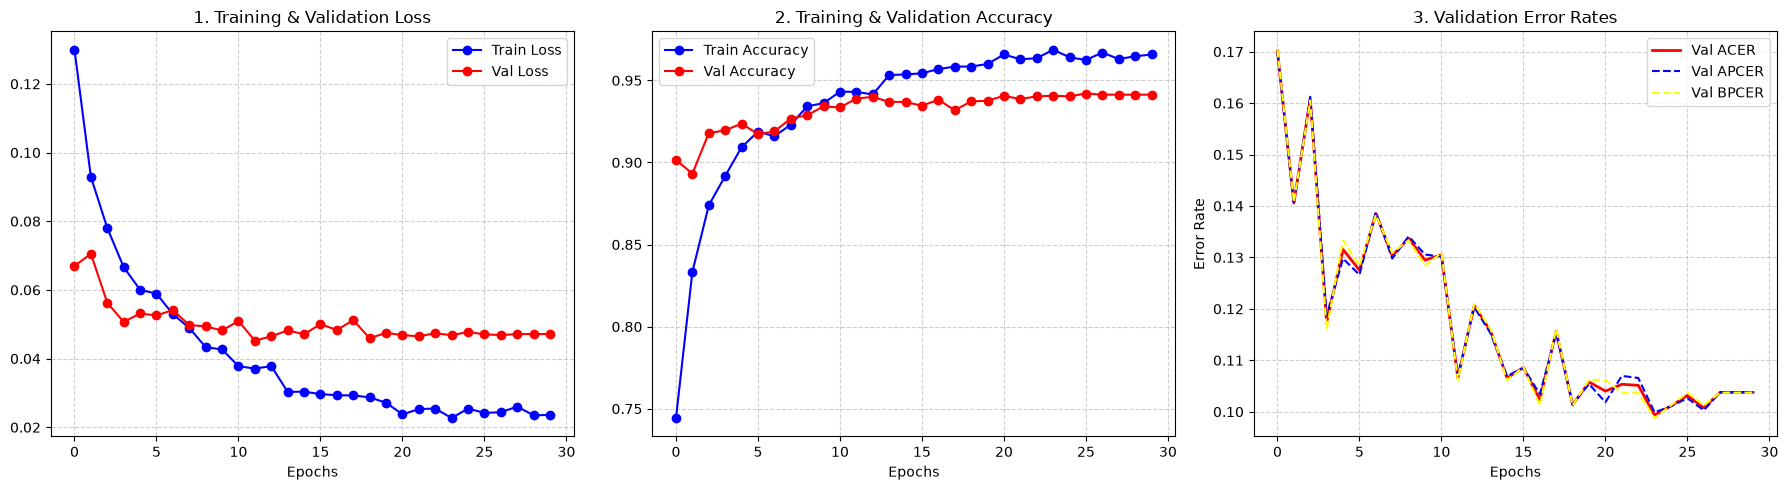

In [15]:
plot_training_history(combined_history, output=str(OUTPUT_DIR / 'training_history.png'))

In [16]:
y_val_prob = model.predict(val_ds)

y_val_list = []
for images, labels in val_ds:
    y_val_list.append(labels.numpy())

y_val_true = np.concatenate(y_val_list)

93/93 ━━━━━━━━━━━━━━━━━━━━ 43s 460ms/step


Đã lưu biểu đồ tại: ../outputs/backbone-model/evaluation_report.png


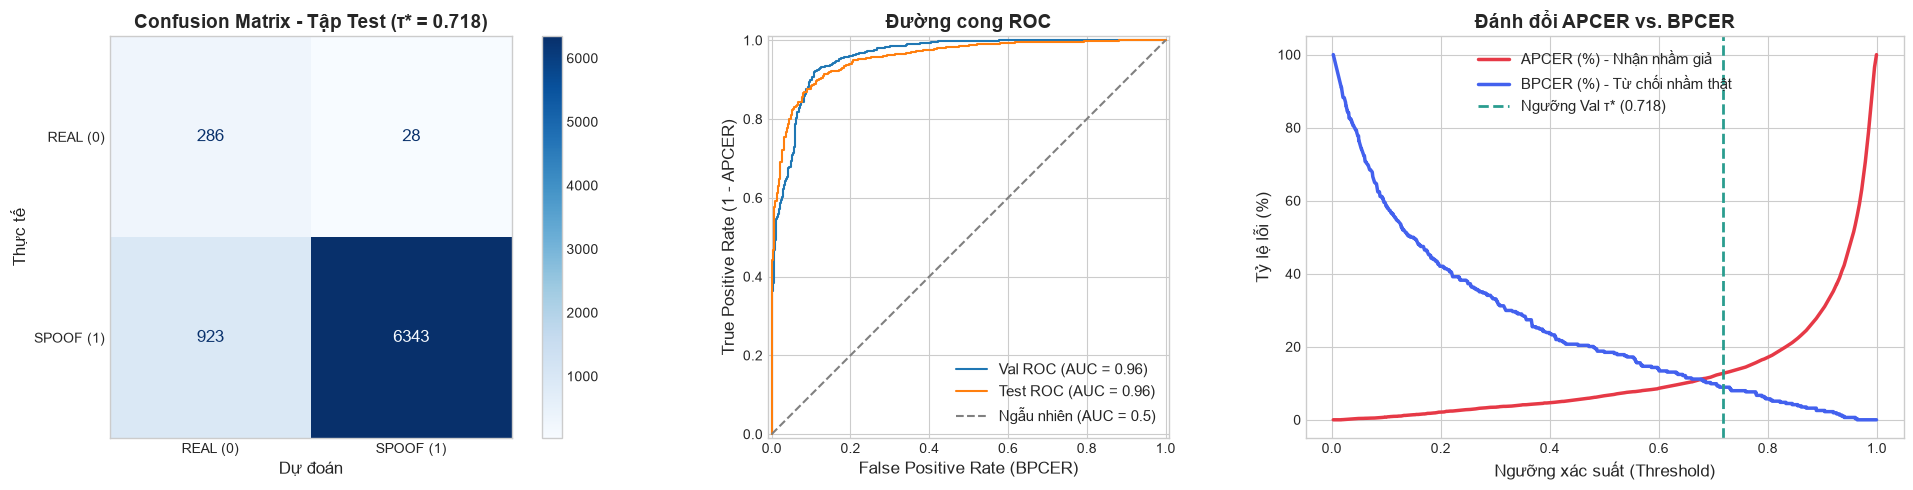

In [17]:
y_test = (y_true, y_prob)
y_val = (y_val_true, y_val_prob)

evaluate_model(y_test, y_val, threshold_best, output=str(OUTPUT_DIR / 'evaluation_report.png'))

In [18]:
metrics = calculate_metrics(y_true, y_prob, threshold_best)

print("Metrics on test set:")
for metric_name, metric_value in metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

Metrics on test set:
EER (%): 11.1465
APCER (%): 12.7030
BPCER (%): 8.9172
ACER (%): 10.8101
AUC (%): 95.6287
ACC (%): 87.4538
